In [1]:
import kagglehub
path = kagglehub.dataset_download("moltean/fruits")
print(path)

Using Colab cache for faster access to the 'fruits' dataset.
/kaggle/input/fruits


In [2]:
import os, random
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image


DATA_DIR = None
for r, dirs, _ in os.walk(path):
    if "Training" in dirs:
        DATA_DIR = os.path.join(r, "Training")
        break

CLASSES = ["Apple Red 1", "Banana 1", "Orange 1", "Kiwi 1", "Blueberry 1"]
paths = {}
for c in CLASSES:
    class_dir = os.path.join(DATA_DIR, c)
    paths[c] = []
    for f in os.listdir(class_dir):
        if f.lower().endswith((".jpg", ".png")):
            paths[c].append(os.path.join(class_dir, f))
counts = {}
for c in CLASSES:
    counts[c] = len(paths[c])
print(counts)

{'Apple Red 1': 492, 'Banana 1': 490, 'Orange 1': 479, 'Kiwi 1': 466, 'Blueberry 1': 462}


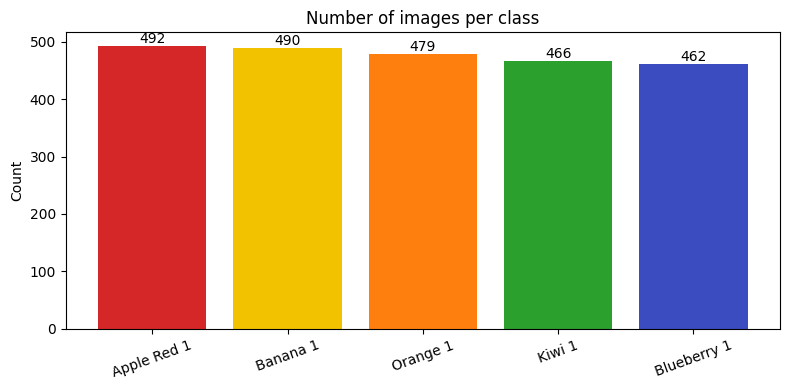

In [3]:
counts = {c: len(p) for c, p in paths.items()}

plt.figure(figsize=(8, 4))
bars = plt.bar(counts.keys(), counts.values(),
               color=["#d62728", "#f2c200", "#ff7f0e", "#2ca02c", "#3b4cc0"])
plt.bar_label(bars)
plt.title("Number of images per class")
plt.ylabel("Count")
plt.xticks(rotation=20)
plt.tight_layout()
plt.show()

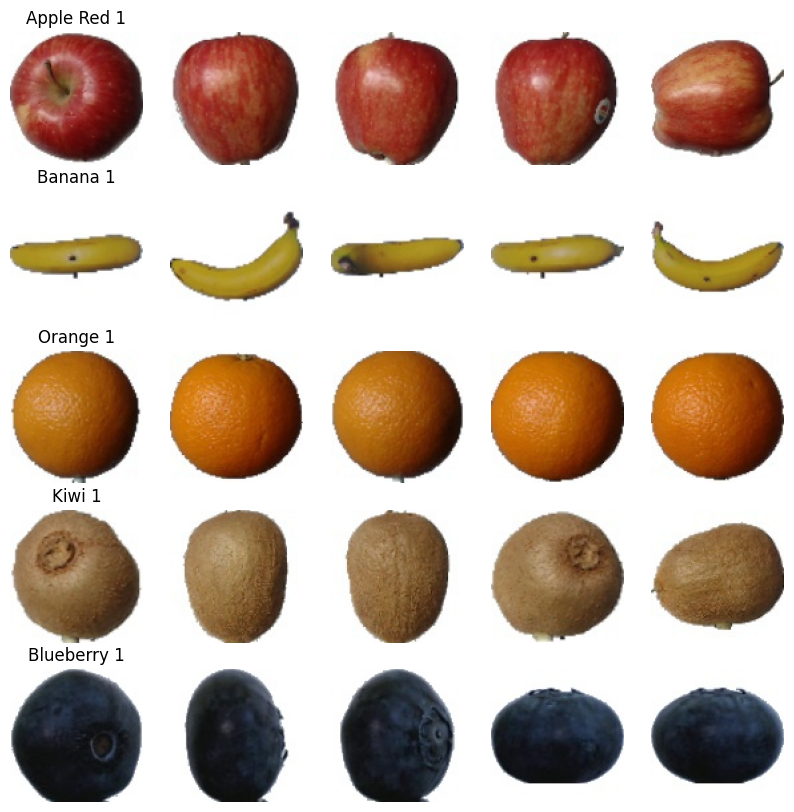

Image sizes found: {(100, 100)}


In [4]:
N = 5
fig, axes = plt.subplots(len(CLASSES), N, figsize=(2 * N, 2 * len(CLASSES)))
for i, c in enumerate(CLASSES):
    for j, p in enumerate(random.sample(paths[c], N)):
        axes[i, j].imshow(Image.open(p).convert("RGB"))
        axes[i, j].axis("off")
        if j == 0:
            axes[i, j].set_title(c)

plt.show()

sizes = set()
for c in CLASSES:
    for p in paths[c]:
        sizes.add(Image.open(p).size)

print("Image sizes found:", sizes)

In [5]:
BINS = 32

def img_hist(img, bins=BINS):
    mask = ~(img > 240).all(axis=2)
    if mask.sum() == 0:
        mask[:] = True
    h = [np.histogram(img[..., ch][mask], bins=bins, range=(0, 256))[0] for ch in range(3)]
    h = np.concatenate(h).astype(np.float32)
    return h / h.sum() * 3

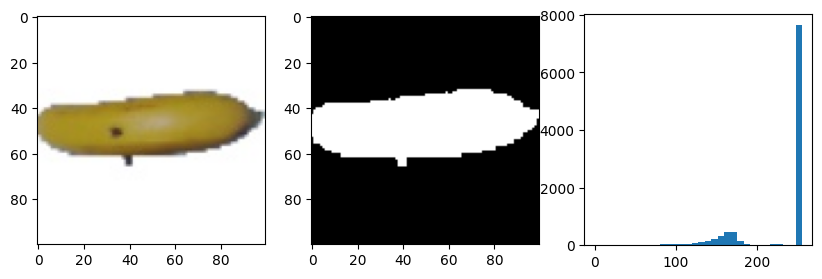

In [6]:
p = random.choice(paths["Banana 1"])
img = np.array(Image.open(p).convert("RGB"))
mask = ~(img > 240).all(axis=2)

fig, ax = plt.subplots(1, 3, figsize=(10, 3))
ax[0].imshow(img)
ax[1].imshow(mask, cmap="gray")
ax[2].hist(img[..., 0].ravel(), bins=32, range=(0, 256))
plt.show()

In [7]:
def mean_hist(file_list, bins=BINS, n=150, seed=13):
    random.seed(seed)
    sample = random.sample(file_list, min(n, len(file_list)))

    all_hists = []
    for p in sample:
        img = np.array(Image.open(p).convert("RGB"))
        all_hists.append(img_hist(img, bins))

    H = np.mean(all_hists, axis=0)
    return H.reshape(3, bins)

hists = {}
for c in CLASSES:
    hists[c] = mean_hist(paths[c])


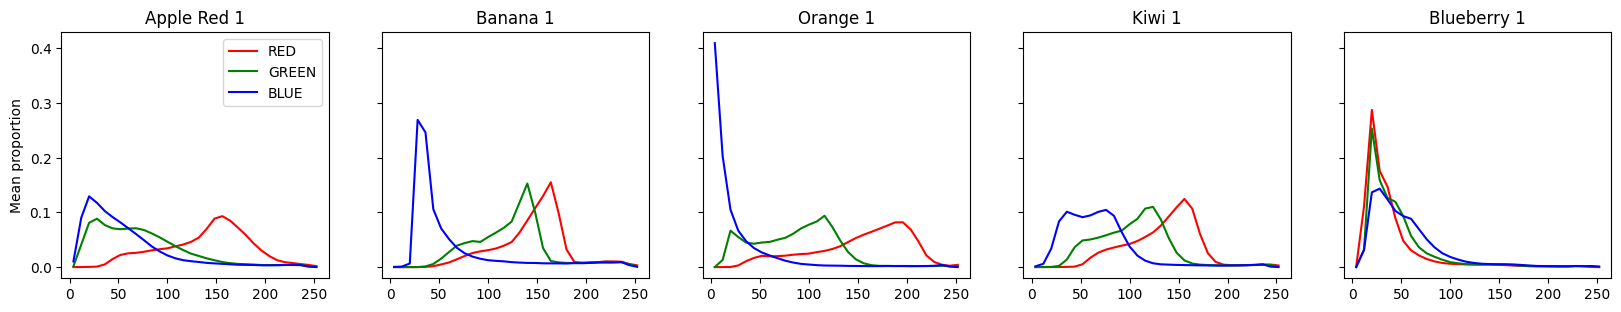

In [8]:
centers = (np.arange(BINS) + 0.5) * (256 / BINS)
fig, axes = plt.subplots(1, len(CLASSES), figsize=(4 * len(CLASSES), 3.2), sharey=True)
for ax, c in zip(axes, CLASSES):
    for ch, col in enumerate(["red", "green", "blue"]):
        ax.plot(centers, hists[c][ch], color=col, label=col.upper())
    ax.set_title(c)
axes[0].set_ylabel("Mean proportion")
axes[0].legend()
plt.show()

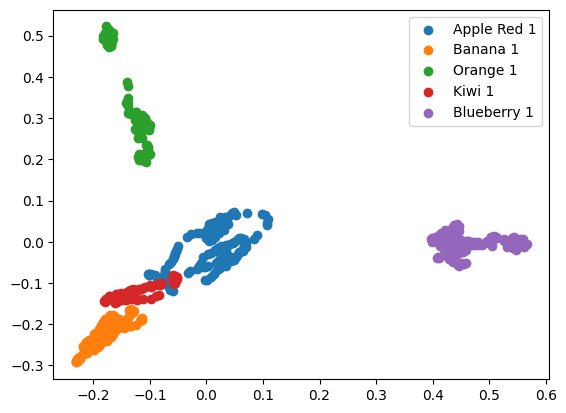

X shape: (750, 96)


In [9]:
from sklearn.decomposition import PCA

X, y = [], []
for ci, c in enumerate(CLASSES):
    for p in random.sample(paths[c], min(150, len(paths[c]))):
        X.append(img_hist(np.array(Image.open(p).convert("RGB"))))
        y.append(ci)
X, y = np.array(X), np.array(y)

Z = PCA(n_components=2).fit_transform(X)

for ci, c in enumerate(CLASSES):
    plt.scatter(Z[y == ci, 0], Z[y == ci, 1], label=c)
plt.legend()
plt.show()
print("X shape:", X.shape)

In [10]:
X, y = [], []
for ci, c in enumerate(CLASSES):
    for p in paths[c]:
        img = Image.open(p).convert("RGB").resize((100, 100))
        X.append(img_hist(np.array(img)))
        y.append(ci)

X = np.array(X)
y = np.array(y)
print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (2389, 96)
y shape: (2389,)


In [11]:
from sklearn.model_selection import train_test_split

TEST_SIZE = 0.20
VAL_SIZE = 0.20


X_temp, X_test, y_temp, y_test = train_test_split(
    X, y, test_size=TEST_SIZE, stratify=y, random_state=42
)


X_train, X_val, y_train, y_val = train_test_split(
    X_temp, y_temp, test_size=VAL_SIZE / (1 - TEST_SIZE), stratify=y_temp, random_state=42
)

print("Train:", X_train.shape)
print("Val:  ", X_val.shape)
print("Test: ", X_test.shape)


for name, labels in [("Train", y_train), ("Val", y_val), ("Test", y_test)]:
    print(name, np.bincount(labels))

Train: (1433, 96)
Val:   (478, 96)
Test:  (478, 96)
Train [295 294 287 280 277]
Val [98 98 96 93 93]
Test [99 98 96 93 92]


In [12]:
import seaborn as sns
import pandas as pd
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.cluster import KMeans
from sklearn.metrics import (accuracy_score, confusion_matrix, classification_report,
                             silhouette_score, adjusted_rand_score)

In [13]:
scaler = StandardScaler().fit(X_train)

X_train_scaled = scaler.transform(X_train)
X_val_scaled = scaler.transform(X_val)
X_test_scaled = scaler.transform(X_test)

In [14]:
lr_val_acc = {}
for C in [0.0001, 0.001, 0.01, 0.1, 1, 10, 100]:
    model = LogisticRegression(C=C, max_iter=3000, random_state=42).fit(X_train_scaled, y_train)
    lr_val_acc[C] = accuracy_score(y_val, model.predict(X_val_scaled))
    print(f"LogReg C={C:<8} val acc = {lr_val_acc[C]:.4f}")
best_C = max(sorted(lr_val_acc), key=lambda c: (lr_val_acc[c], -c))
print("Best C:", best_C)

knn_val_acc = {}
for weights in ["uniform", "distance"]:
    for k in [1, 3, 5, 7, 9, 11, 15, 21]:
        model = KNeighborsClassifier(n_neighbors=k, weights=weights).fit(X_train_scaled, y_train)
        knn_val_acc[(k, weights)] = accuracy_score(y_val, model.predict(X_val_scaled))
        print(f"KNN k={k:<3} weights={weights:<9} val acc = {knn_val_acc[(k, weights)]:.4f}")
best_k, best_w = max(knn_val_acc, key=lambda kw: (knn_val_acc[kw], kw[0], kw[1] == "uniform"))
print("Best KNN:", best_k, best_w)

LogReg C=0.0001   val acc = 0.9937
LogReg C=0.001    val acc = 1.0000
LogReg C=0.01     val acc = 1.0000
LogReg C=0.1      val acc = 1.0000
LogReg C=1        val acc = 1.0000
LogReg C=10       val acc = 1.0000
LogReg C=100      val acc = 1.0000
Best C: 0.001
KNN k=1   weights=uniform   val acc = 1.0000
KNN k=3   weights=uniform   val acc = 1.0000
KNN k=5   weights=uniform   val acc = 1.0000
KNN k=7   weights=uniform   val acc = 1.0000
KNN k=9   weights=uniform   val acc = 1.0000
KNN k=11  weights=uniform   val acc = 1.0000
KNN k=15  weights=uniform   val acc = 1.0000
KNN k=21  weights=uniform   val acc = 1.0000
KNN k=1   weights=distance  val acc = 1.0000
KNN k=3   weights=distance  val acc = 1.0000
KNN k=5   weights=distance  val acc = 1.0000
KNN k=7   weights=distance  val acc = 1.0000
KNN k=9   weights=distance  val acc = 1.0000
KNN k=11  weights=distance  val acc = 1.0000
KNN k=15  weights=distance  val acc = 1.0000
KNN k=21  weights=distance  val acc = 1.0000
Best KNN: 21 uniform


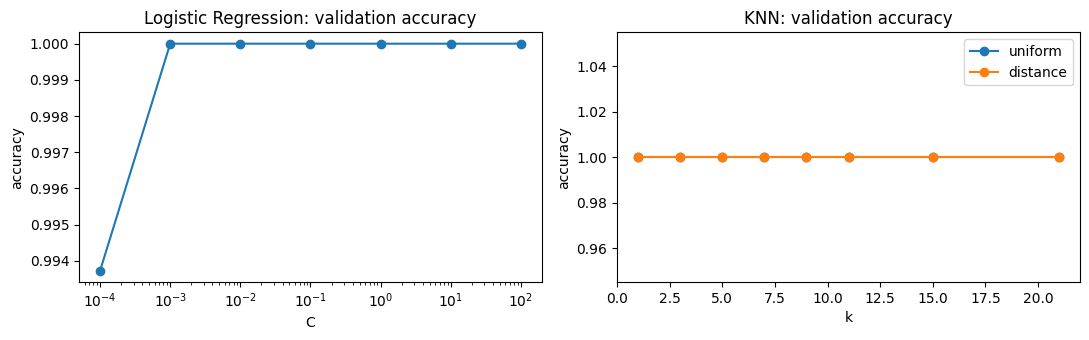

In [15]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
ax[0].semilogx(list(lr_val_acc), list(lr_val_acc.values()), "o-")
ax[0].set(title="Logistic Regression: validation accuracy", xlabel="C", ylabel="accuracy")
for weights in ["uniform", "distance"]:
    ks = [k for k, ww in knn_val_acc if ww == weights]
    ax[1].plot(ks, [knn_val_acc[(k, weights)] for k in ks], "o-", label=weights)
ax[1].set(title="KNN: validation accuracy", xlabel="k", ylabel="accuracy")
ax[1].legend()
plt.tight_layout()
plt.show()

===== Logistic Regression =====
Test accuracy: 1.0
              precision    recall  f1-score   support

 Apple Red 1     1.0000    1.0000    1.0000        99
    Banana 1     1.0000    1.0000    1.0000        98
    Orange 1     1.0000    1.0000    1.0000        96
      Kiwi 1     1.0000    1.0000    1.0000        93
 Blueberry 1     1.0000    1.0000    1.0000        92

    accuracy                         1.0000       478
   macro avg     1.0000    1.0000    1.0000       478
weighted avg     1.0000    1.0000    1.0000       478



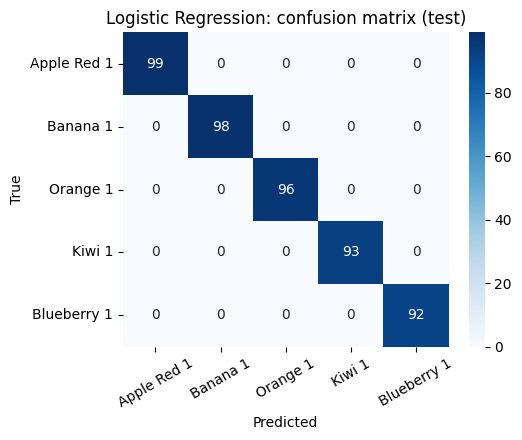

===== KNN =====
Test accuracy: 1.0
              precision    recall  f1-score   support

 Apple Red 1     1.0000    1.0000    1.0000        99
    Banana 1     1.0000    1.0000    1.0000        98
    Orange 1     1.0000    1.0000    1.0000        96
      Kiwi 1     1.0000    1.0000    1.0000        93
 Blueberry 1     1.0000    1.0000    1.0000        92

    accuracy                         1.0000       478
   macro avg     1.0000    1.0000    1.0000       478
weighted avg     1.0000    1.0000    1.0000       478



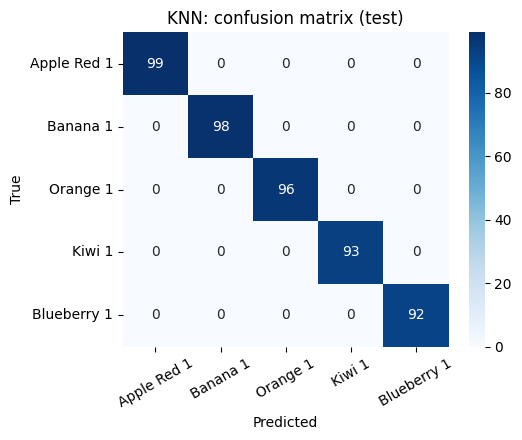

In [16]:
lr_model = LogisticRegression(C=best_C, max_iter=3000, random_state=42).fit(X_train_scaled, y_train)
knn_model = KNeighborsClassifier(n_neighbors=best_k, weights=best_w).fit(X_train_scaled, y_train)

test_preds = {}
for name, model in [("Logistic Regression", lr_model), ("KNN", knn_model)]:
    y_pred = model.predict(X_test_scaled)
    test_preds[name] = y_pred
    print("=====", name, "=====")
    print("Test accuracy:", round(accuracy_score(y_test, y_pred), 4))
    print(classification_report(y_test, y_pred, target_names=CLASSES, digits=4))

    plt.figure(figsize=(5.5, 4.5))
    sns.heatmap(confusion_matrix(y_test, y_pred), annot=True, fmt="d", cmap="Blues",
                xticklabels=CLASSES, yticklabels=CLASSES)
    plt.title(name + ": confusion matrix (test)")
    plt.xlabel("Predicted")
    plt.ylabel("True")
    plt.xticks(rotation=30)
    plt.tight_layout()
    plt.show()

y_pred_lr, y_pred_knn = test_preds["Logistic Regression"], test_preds["KNN"]

cluster 0 -> Orange 1     (size 287, purity 1.000)
cluster 1 -> Apple Red 1  (size 282, purity 0.993)
cluster 2 -> Blueberry 1  (size 277, purity 1.000)
cluster 3 -> Banana 1     (size 294, purity 1.000)
cluster 4 -> Kiwi 1       (size 293, purity 0.949)
K-Means accuracy (train): 0.9881
K-Means accuracy (test):  0.9854
Silhouette (train): 0.3746
Silhouette (test):  0.3617
Adjusted Rand Index (test): 0.9643


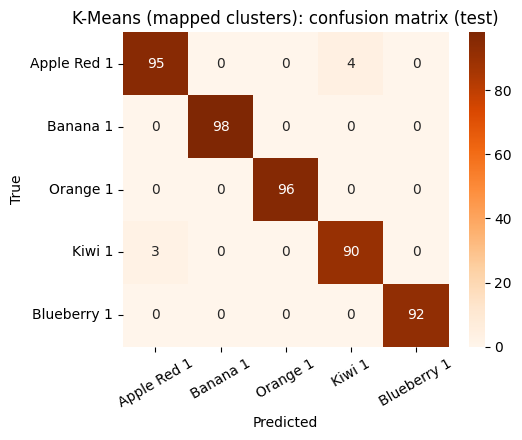

In [20]:
kmeans_model = KMeans(n_clusters=5, n_init=10, random_state=42).fit(X_train_scaled)

cluster_to_label = np.zeros(5, dtype=int)
for k in range(5):
    cluster_labels = y_train[kmeans_model.labels_ == k]
    cluster_to_label[k] = np.bincount(cluster_labels, minlength=5).argmax()
    print(f"cluster {k} -> {CLASSES[cluster_to_label[k]]:12s} (size {len(cluster_labels)}, purity {np.bincount(cluster_labels).max() / len(cluster_labels):.3f})")

test_clusters = kmeans_model.predict(X_test_scaled)
y_pred_km = cluster_to_label[test_clusters]

print("K-Means accuracy (train):", round(accuracy_score(y_train, cluster_to_label[kmeans_model.labels_]), 4))
print("K-Means accuracy (test): ", round(accuracy_score(y_test, y_pred_km), 4))
print("Silhouette (train):", round(silhouette_score(X_train_scaled, kmeans_model.labels_), 4))
print("Silhouette (test): ", round(silhouette_score(X_test_scaled, test_clusters), 4))
print("Adjusted Rand Index (test):", round(adjusted_rand_score(y_test, test_clusters), 4))

plt.figure(figsize=(5.5, 4.5))
sns.heatmap(confusion_matrix(y_test, y_pred_km), annot=True, fmt="d", cmap="Oranges",
            xticklabels=CLASSES, yticklabels=CLASSES)
plt.title("K-Means (mapped clusters): confusion matrix (test)")
plt.xlabel("Predicted")
plt.ylabel("True")
plt.xticks(rotation=30)
plt.tight_layout()
plt.show()

In [18]:
results_table = pd.DataFrame({
    "Model": ["Logistic Regression", "KNN", "K-Means (mapped)"],
    "Chosen hyperparameters": [f"C={best_C}", f"k={best_k}, weights={best_w}", "n_clusters=5"],
    "Test accuracy": [accuracy_score(y_test, y_pred_lr), accuracy_score(y_test, y_pred_knn),
                      accuracy_score(y_test, y_pred_km)],
})
results_table

,Model,Chosen hyperparameters,Test accuracy
0,Logistic Regression,C=0.001,1.000000
1,KNN,"k=21, weights=uniform",1.000000
2,K-Means (mapped),n_clusters=5,0.985356
